In [1]:
import os
import subprocess
import glob
import xarray as xr
import numpy as np
from collections import defaultdict
from typing import Dict, List, Tuple

In [2]:
# --- Configuration ---
BASE_DIR1 = "/glade/derecho/scratch/bgong/amip_s2s_ensembles"
BASE_DIR2 = "/glade/derecho/scratch/bgong/amip_s2s_train_scratch"

TARGET_VARIABLE = "PRATEsfc_24h"
MEMBERS_COUNT = 10 # Seeds 0 through 9
GRID_FILE = "/glade/work/rajatm/benchmark-dev/metrics/monsoon/grid_2deg_india.txt"  # <<--- IMPORTANT: Change this path!

In [3]:
ds1 = xr.open_dataset('/glade/derecho/scratch/bgong/amip_s2s_ensembles/20190506/ensemble_20190506_seed9.nc')
ds2 = xr.open_dataset('/glade/derecho/scratch/bgong/amip_s2s_train_scratch/20190506/ensemble_20190506_seed9.nc')

In [6]:
ds1

<xarray.Dataset> Size: 7GB
Dimensions:                  (member: 4, time: 46, lat: 180, lon: 360, plev: 26)
Coordinates:
  * member                   (member) int32 16B 0 1 2 3
  * time                     (time) datetime64[ns] 368B 2019-05-06 ... 2019-0...
  * plev                     (plev) float64 208B 500.0 700.0 ... 9.75e+04 1e+05
  * lat                      (lat) float64 1kB -89.5 -88.5 -87.5 ... 88.5 89.5
  * lon                      (lon) float64 3kB 0.5 1.5 2.5 ... 357.5 358.5 359.5
Data variables: (12/26)
    skin_temperature         (member, time, lat, lon) float32 48MB ...
    surface_pressure         (member, time, lat, lon) float32 48MB ...
    2m_temperature           (member, time, lat, lon) float32 48MB ...
    2m_specific_humidity     (member, time, lat, lon) float32 48MB ...
    10m_u_component_of_wind  (member, time, lat, lon) float32 48MB ...
    10m_v_component_of_wind  (member, time, lat, lon) float32 48MB ...
    ...                       ...
    hcc_24h                  (member, time, lat, lon) float32 48MB ...
    lcc_24h                  (member, time, lat, lon) float32 48MB ...
    mcc_24h                  (member, time, lat, lon) float32 48MB ...
    mn2t_24h                 (member, time, lat, lon) float32 48MB ...
    mx2t_24h                 (member, time, lat, lon) float32 48MB ...
    mxtpr_24h                (member, time, lat, lon) float32 48MB ...
Attributes:
    Conventions:  CF-1.8
    source:       amip S2S ensemble rollout
    start_date:   2019-05-06T00:00:00
    n_ensemble:   4
    frequency:    day
    grid_label:   gn

In [42]:
ds.time

<xarray.DataArray 'time' (time: 46)> Size: 368B
array(['2019-05-06T00:00:00.000000000', '2019-05-07T00:00:00.000000000',
       '2019-05-08T00:00:00.000000000', '2019-05-09T00:00:00.000000000',
       '2019-05-10T00:00:00.000000000', '2019-05-11T00:00:00.000000000',
       '2019-05-12T00:00:00.000000000', '2019-05-13T00:00:00.000000000',
       '2019-05-14T00:00:00.000000000', '2019-05-15T00:00:00.000000000',
       '2019-05-16T00:00:00.000000000', '2019-05-17T00:00:00.000000000',
       '2019-05-18T00:00:00.000000000', '2019-05-19T00:00:00.000000000',
       '2019-05-20T00:00:00.000000000', '2019-05-21T00:00:00.000000000',
       '2019-05-22T00:00:00.000000000', '2019-05-23T00:00:00.000000000',
       '2019-05-24T00:00:00.000000000', '2019-05-25T00:00:00.000000000',
       '2019-05-26T00:00:00.000000000', '2019-05-27T00:00:00.000000000',
       '2019-05-28T00:00:00.000000000', '2019-05-29T00:00:00.000000000',
       '2019-05-30T00:00:00.000000000', '2019-05-31T00:00:00.000000000',
       '2019-06-01T00:00:00.000000000', '2019-06-02T00:00:00.000000000',
       '2019-06-03T00:00:00.000000000', '2019-06-04T00:00:00.000000000',
       '2019-06-05T00:00:00.000000000', '2019-06-06T00:00:00.000000000',
       '2019-06-07T00:00:00.000000000', '2019-06-08T00:00:00.000000000',
       '2019-06-09T00:00:00.000000000', '2019-06-10T00:00:00.000000000',
       '2019-06-11T00:00:00.000000000', '2019-06-12T00:00:00.000000000',
       '2019-06-13T00:00:00.000000000', '2019-06-14T00:00:00.000000000',
       '2019-06-15T00:00:00.000000000', '2019-06-16T00:00:00.000000000',
       '2019-06-17T00:00:00.000000000', '2019-06-18T00:00:00.000000000',
       '2019-06-19T00:00:00.000000000', '2019-06-20T00:00:00.000000000'],
      dtype='datetime64[ns]')
Coordinates:
  * time     (time) datetime64[ns] 368B 2019-05-06 2019-05-07 ... 2019-06-20

In [21]:
print(ds["PRATEsfc_24h"].dims)

('member', 'time', 'lat', 'lon')


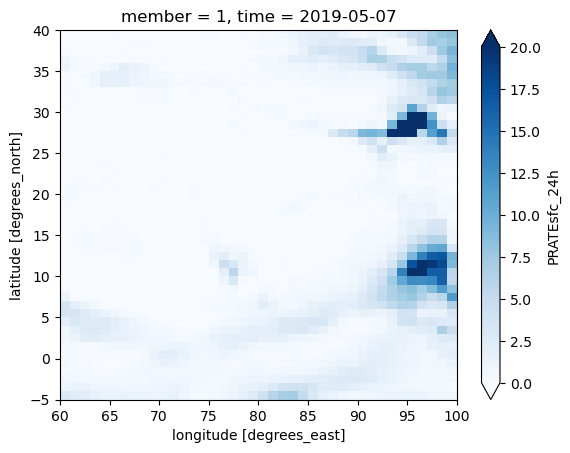

In [7]:
(ds1['PRATEsfc_24h'].sel(lon = slice(60,100), lat = slice(-5,40) ,member=1, time = '2019-05-07T00:00:00.000000000')*86400).plot(vmin=0, vmax=20, cmap = 'Blues')

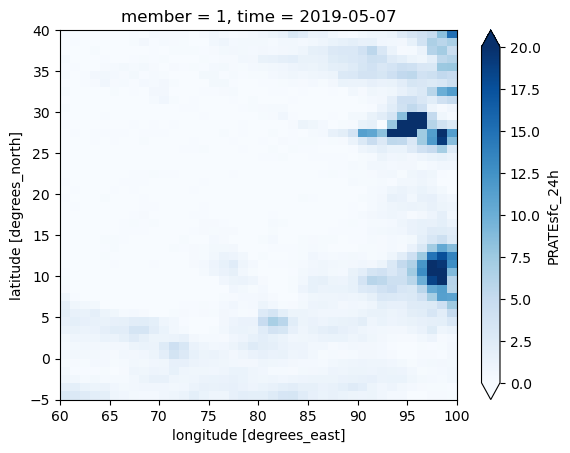

In [8]:
(ds2['PRATEsfc_24h'].sel(lon = slice(60,100), lat = slice(-5,40) ,member=1, time = '2019-05-07T00:00:00.000000000')*86400).plot(vmin=0, vmax=20, cmap = 'Blues')

In [9]:
ds3 = xr.open_dataset("/glade/work/rajatm/benchmark-dev/metrics/monsoon/data_files/regrid_out/amip_s2s_clim/2019.nc")
ds4 = xr.open_dataset("/glade/work/rajatm/benchmark-dev/metrics/monsoon/data_files/regrid_out/amip_s2s_train_scratch/2019.nc")

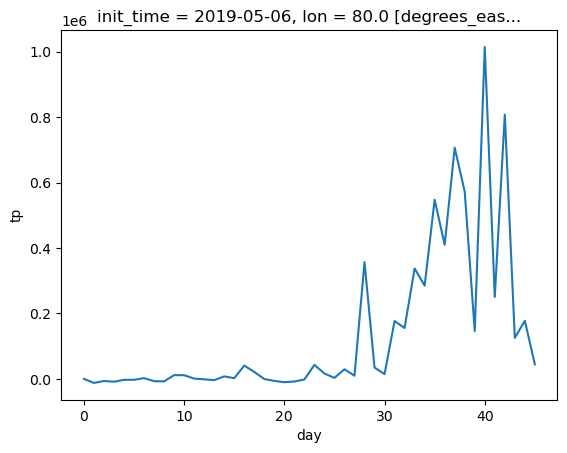

In [11]:
(ds3['tp'].sel(lat=20, lon=80, member=2, init_time = '2019-05-06T00:00:00.000000000')*86400).plot()

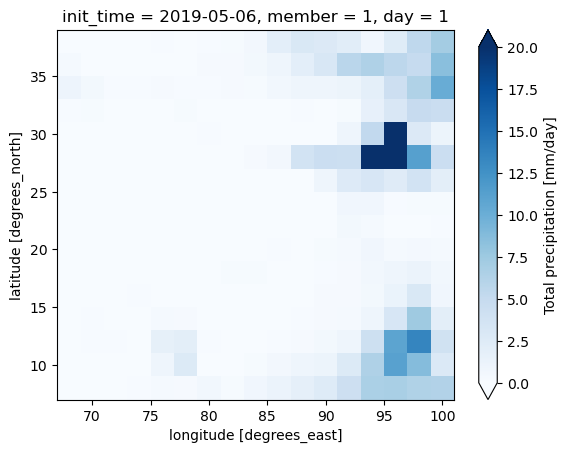

In [13]:
(ds3['tp'].sel(member=1, init_time = '2019-05-06T00:00:00.000000000', day = 1)).plot(vmin=0, vmax=20, cmap = 'Blues')

In [14]:
# Load IMD (ground truth) data
year = 2019
imd_file = f"/glade/work/rajatm/benchmark-dev/metrics/monsoon/data_files/IMD_2by2/data_{year}.nc"
imd_ds = xr.open_dataset(imd_file)

print("IMD dataset variables:", list(imd_ds.data_vars.keys()))
print("IMD dataset dimensions:", dict(imd_ds.dims))
print("IMD dataset coordinates:", list(imd_ds.coords.keys()))

# Check the structure of IMD data
print("\nIMD data structure:")
print(imd_ds)

IMD dataset variables: ['RAINFALL']
IMD dataset dimensions: {'TIME': 365, 'latitude': 16, 'longitude': 17}
IMD dataset coordinates: ['TIME', 'longitude', 'latitude']

IMD data structure:
<xarray.Dataset> Size: 797kB
Dimensions:    (TIME: 365, latitude: 16, longitude: 17)
Coordinates:
  * TIME       (TIME) datetime64[ns] 3kB 2019-01-01 2019-01-02 ... 2019-12-31
  * longitude  (longitude) int64 136B 68 70 72 74 76 78 ... 90 92 94 96 98 100
  * latitude   (latitude) int64 128B 8 10 12 14 16 18 20 ... 28 30 32 34 36 38
Data variables:
    RAINFALL   (TIME, latitude, longitude) float64 794kB ...
Attributes:
    regrid_method:  conservative


/glade/derecho/scratch/rajatm/tmp/ipykernel_23864/3069941070.py:7: FutureWarning: The return type of `Dataset.dims` will be changed to return a set of dimension names in future, in order to be more consistent with `DataArray.dims`. To access a mapping from dimension names to lengths, please use `Dataset.sizes`.
  print("IMD dataset dimensions:", dict(imd_ds.dims))


In [17]:
import matplotlib.pyplot as plt
import pandas as pd
# Updated function for multiple initialization comparisons
def compare_model_imd_multiple_inits(ds, imd_ds, lat_sel=20, lon_sel=80, n_inits=3):
    """
    Compare model forecasts with IMD observations for multiple initialization times
    """
    
    fig, axes = plt.subplots(n_inits, 1, figsize=(12, 4*n_inits))
    if n_inits == 1:
        axes = [axes]
    
    ds_stats = ds["tp"]
    
    for i in range(n_inits):
        init_idx = i * (len(ds.init_time) // n_inits)  # Spread out init times
        
        # Model data
        selected_model = ds_stats.isel(init_time=init_idx).sel(lat=lat_sel, lon=lon_sel, method='nearest')
        ensemble_mean = selected_model.mean(dim='member')
        p2_5 = selected_model.quantile(0.025, dim='member')
        p97_5 = selected_model.quantile(0.975, dim='member')
        
        # Get dates
        init_date = pd.to_datetime(ds.init_time[init_idx].values)
        forecast_dates = pd.date_range(start=init_date, periods=len(ensemble_mean), freq='D')
        
        # IMD data (note: using 'RAINFALL', 'TIME', 'latitude', 'longitude')
        imd_selected = imd_ds['RAINFALL'].sel(latitude=lat_sel, longitude=lon_sel, method='nearest')
        imd_period = imd_selected.sel(TIME=slice(init_date, forecast_dates[-1]))
        
        # Plot
        axes[i].plot(forecast_dates, ensemble_mean.values, 
                    'b-', label='Model Mean', linewidth=2)
        axes[i].fill_between(forecast_dates, p2_5.values, p97_5.values,
                           alpha=0.3, color='blue', label='95%')
        
        if len(imd_period.TIME) > 0:
            axes[i].plot(imd_period.TIME, imd_period.values, 
                        'ro-', label='IMD Obs', markersize=3)
        
        axes[i].set_title(f'Init: {init_date.strftime("%Y-%m-%d")}')
        axes[i].set_ylabel('Precip (mm/day)')
        axes[i].legend()
        axes[i].grid(True, alpha=0.3)
        
        if i == n_inits - 1:
            axes[i].set_xlabel('Date')
    
    plt.suptitle(f'Model vs IMD Comparison - Multiple Initializations\n'
                f'Location: {lat_sel}°N, {lon_sel}°E')
    plt.tight_layout()
    plt.show()

# Run the comparison


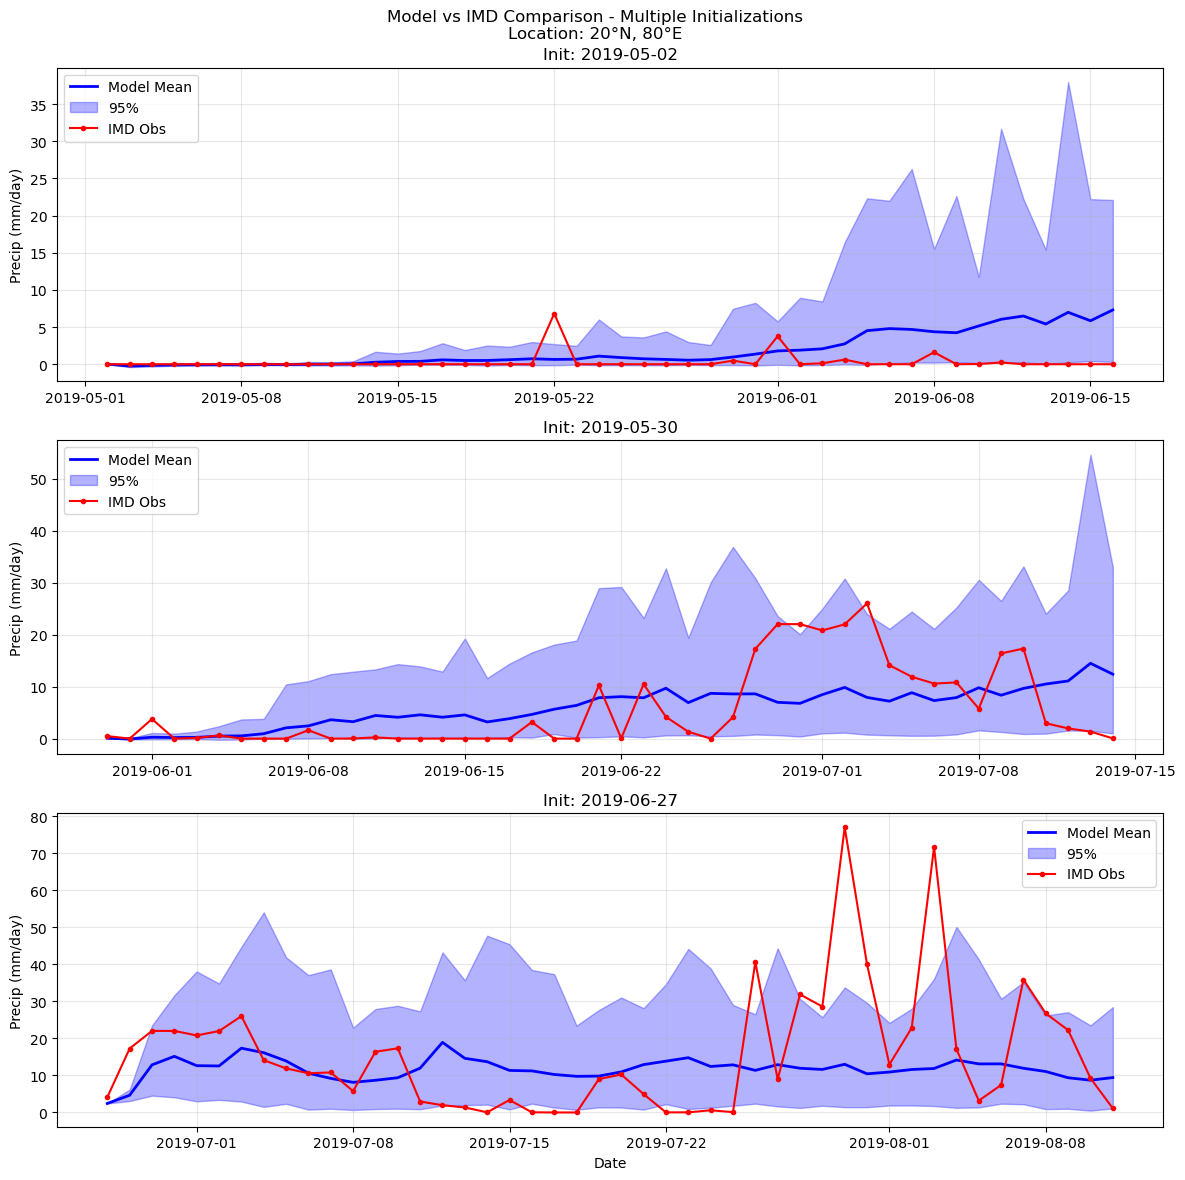

In [18]:
compare_model_imd_multiple_inits(ds3, imd_ds, lat_sel=20, lon_sel=80, n_inits=3)

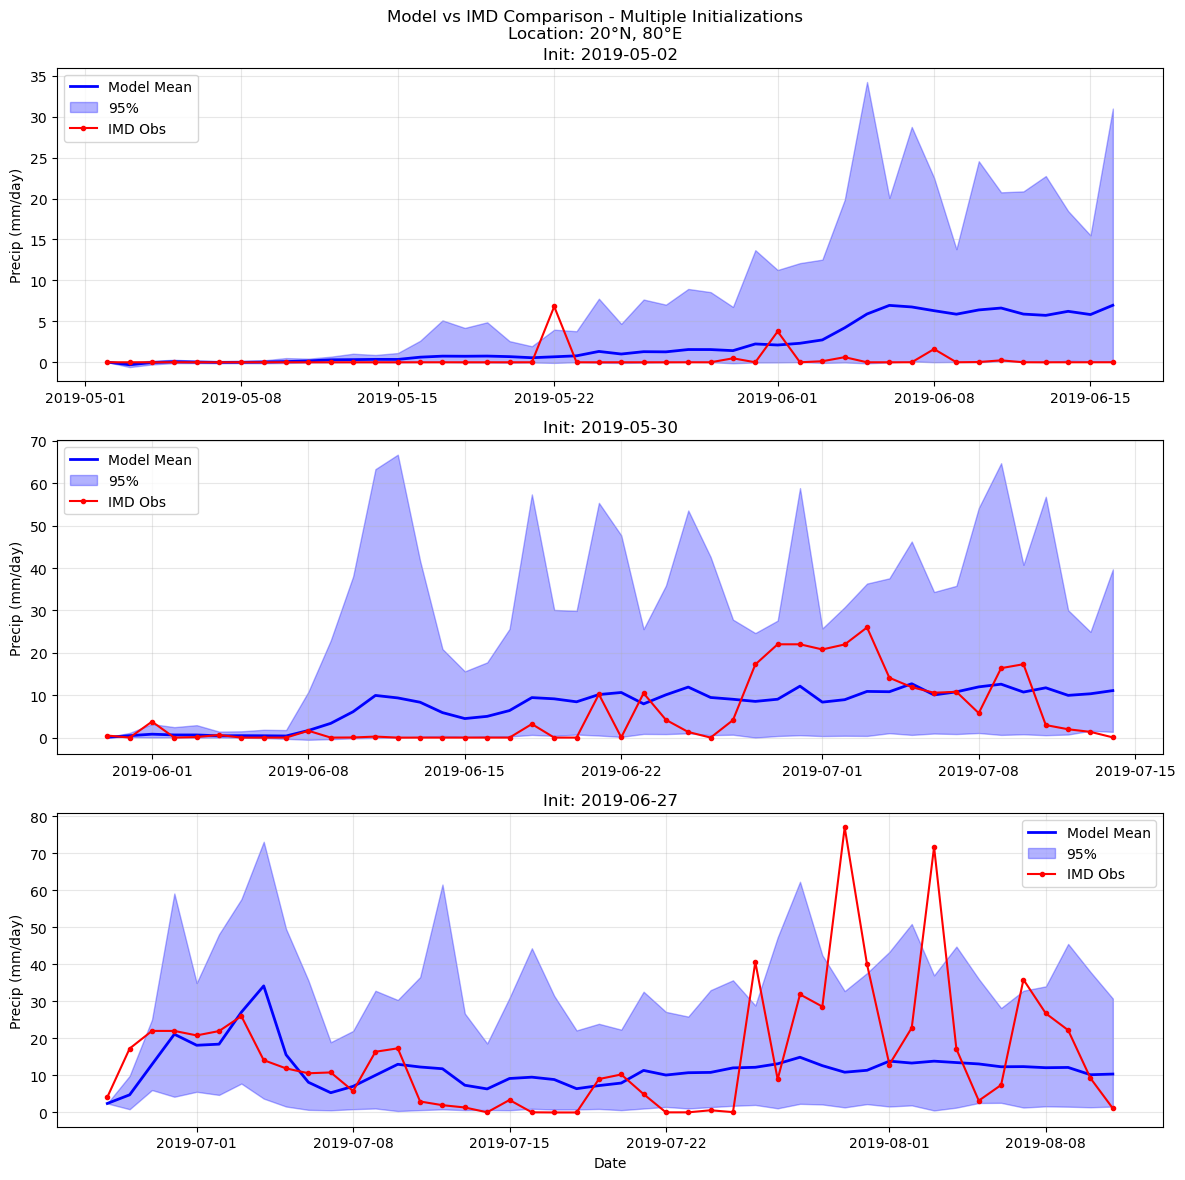

In [19]:
compare_model_imd_multiple_inits(ds4, imd_ds, lat_sel=20, lon_sel=80, n_inits=3)

Text(0.5, 1.0, 'Precipitation comparison (20N, 80E)')

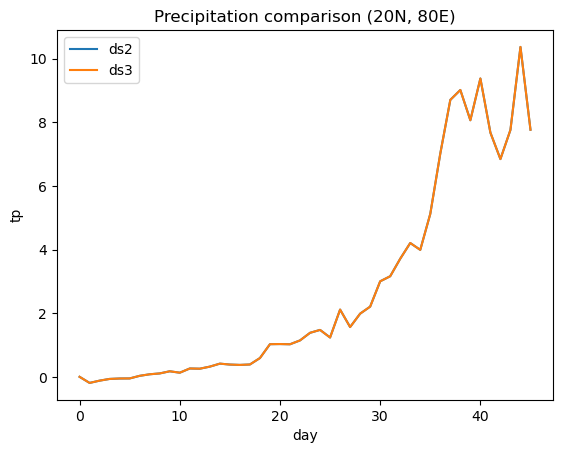

In [114]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots()

(ds2['PRATEsfc_24h']
 .sel(lat=20, lon=80, init_time='2019-05-06T00:00:00.000000000')
 .mean(dim='member') * 86400
).plot(ax=ax, label='ds2')

(ds3['tp']
 .sel(lat=20, lon=80, init_time='2019-05-06T00:00:00.000000000')
 .mean(dim='member') 
).plot(ax=ax, label='ds3')

ax.legend()
ax.set_title("Precipitation comparison (20N, 80E)")

In [110]:
ds2

<xarray.Dataset> Size: 52MB
Dimensions:       (init_time: 26, lon: 17, lat: 16, member: 40, day: 46)
Coordinates:
  * init_time     (init_time) datetime64[ns] 208B 2019-05-02 ... 2019-07-29
  * lon           (lon) float64 136B 68.0 70.0 72.0 74.0 ... 96.0 98.0 100.0
  * lat           (lat) float64 128B 8.0 10.0 12.0 14.0 ... 32.0 34.0 36.0 38.0
  * member        (member) int64 320B 0 1 2 3 4 5 6 7 ... 33 34 35 36 37 38 39
  * day           (day) int64 368B 0 1 2 3 4 5 6 7 8 ... 38 39 40 41 42 43 44 45
Data variables:
    PRATEsfc_24h  (init_time, member, day, lat, lon) float32 52MB 9.317e-06 ....

In [109]:
ds3.member

<xarray.DataArray 'member' (member: 40)> Size: 160B
array([0, 1, 2, 3, 0, 1, 2, 3, 0, 1, 2, 3, 0, 1, 2, 3, 0, 1, 2, 3, 0, 1, 2, 3,
       0, 1, 2, 3, 0, 1, 2, 3, 0, 1, 2, 3, 0, 1, 2, 3], dtype=int32)
Coordinates:
  * member   (member) int32 160B 0 1 2 3 0 1 2 3 0 1 2 ... 1 2 3 0 1 2 3 0 1 2 3
    seed     (member) int64 320B ...
Attributes:
    long_name:  ensemble member index
    axis:       Z

Text(0.5, 1.0, 'Precipitation comparison (20N, 80E)')

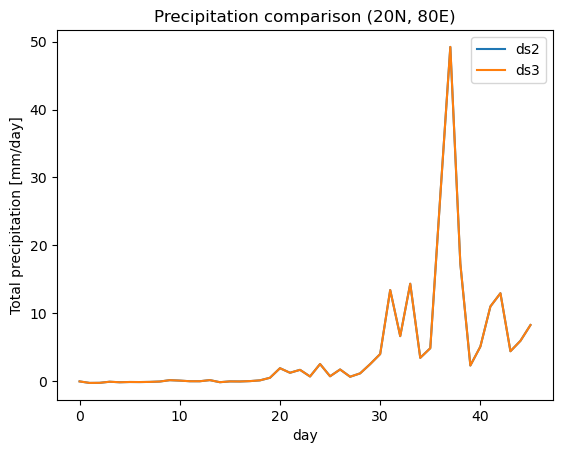

In [118]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots()
mem_id = 15
(ds2['PRATEsfc_24h']
 .sel(lat=20, lon=80, init_time='2019-05-06T00:00:00.000000000',member = mem_id) * 86400
).plot(ax=ax, label='ds2')

(ds3['tp']
 .sel(lat=20, lon=80, init_time='2019-05-06T00:00:00.000000000',member = mem_id)
).plot(ax=ax, label='ds3')

ax.legend()
ax.set_title("Precipitation comparison (20N, 80E)")